<div align="center">

# **Análisis y Procesamiento de Señales**

## **Trabajo Semanal 7: Diseño y Evaluación de Filtros Digitales IIR y FIR para el Procesamiento de ECG**

</div>

<br>
<br>

**Alumnos:** Germán Fiore, Pedro Joaquín Cannavo y Sebastián Roca Garza  
**Especialidad:** Ingeniería Biomédica e Ingeniería Electrónica  
**Fecha:** 11/11/2026  

---

## **1. Objetivos del Trabajo**

El objetivo principal de este trabajo práctico es diseñar, implementar y comparar distintos filtros digitales —tanto de respuesta al impulso infinita (IIR) como finita (FIR)— para limpiar un registro electrocardiográfico (ECG) tomado durante una prueba de esfuerzo (ergometría).

En concreto, buscamos:
1. **Plantear una plantilla de diseño pasa-banda** coherente con el ancho de banda diagnóstico del ECG que estimamos previamente en la TS5, de forma tal de eliminar la deriva de línea de base y las interferencias de alta frecuencia sin deformar las ondas de interés clínico.
2. **Sintetizar y comparar filtros IIR** bajo las aproximaciones clásicas de módulo de **Butterworth**, **Chebyshev Tipo I** y **Cauer (Elíptica)**, trabajando con secciones de segundo orden (`SOS`) y aplicando un filtrado bidireccional de fase cero (`sosfiltfilt`).
3. **Sintetizar y comparar filtros FIR** de fase lineal estricta mediante el método de **ventana de Kaiser** (`firwin2`) y el de **cuadrados mínimos** (`firls`), compensando a mano el retardo de grupo constante que introducen.
4. **Evaluar el rendimiento en el tiempo** sobre la señal real `ecg_lead`, revisando por un lado qué tan inocuos son los filtros en zonas tranquilas (sin ruido) y, por el otro, cómo logran rescatar la morfología del latido en los tramos más contaminados de la ergometría.

---

## **2. Introducción Teórica y Fisiológica**

### **2.1 Fisiología de la Señal ECG y Contaminaciones en Ergometría**

El electrocardiograma (ECG) registra la actividad eléctrica del músculo cardíaco desde la superficie corporal. En un latido normal nos interesa distinguir principalmente tres estructuras:
- **Onda P:** corresponde a la despolarización de las aurículas. Es una onda suave, de baja amplitud y contenido frecuencial bajo (aproximadamente entre $0.5$ y $10\text{ Hz}$).
- **Complejo QRS:** refleja la despolarización ventricular. Por su cambio rápido y gran amplitud, es la parte que concentra la mayor parte de la energía útil del trazado, principalmente en la banda de $1\text{ Hz}$ a $30\text{–}35\text{ Hz}$.
- **Onda T y Segmento ST:** representan la repolarización de los ventrículos. El segmento ST conecta el final del QRS con el inicio de la onda T y normalmente debe mantenerse plano sobre el nivel isoeléctrico ($0\text{ mV}$). Cualquier desnivel o deformación en el ST es un indicador clínico clave de isquemia miocárdica, por lo que es fundamental que el filtro no lo distorsione.

Como este registro pertenece a una **ergometría**, a medida que el paciente corre o hace esfuerzo físico aparecen varias fuentes de contaminación bastante severas:
1. **Deriva de la línea de base ($< 0.5\text{ Hz}$):** oscilación lenta que sube y baja todo el registro, causada por los movimientos respiratorios del tórax y por variaciones en la impedancia piel-electrodo debido a la transpiración.
2. **Artefactos de movimiento ($1\text{–}10\text{ Hz}$):** tirones o desplazamientos mecánicos de los cables y electrodos durante el ejercicio.
3. **Ruido electromiográfico (EMG, $> 30\text{ Hz}$):** actividad eléctrica de alta frecuencia generada por la contracción de los músculos esqueléticos del tórax y las extremidades.
4. **Interferencia de red eléctrica ($50\text{ Hz}$):** acople capacitivo e inductivo de la línea de alimentación domiciliaria.

---

### **2.2 Propiedades de los Filtros IIR y Filtrado Bidireccional de Fase Cero**

Los filtros de Respuesta al Impulso Infinita (IIR) utilizan tanto ceros como polos en el plano $z$, lo que les permite lograr caídas espectrales muy abruptas con un orden muy bajo (y por lo tanto, con muy poco costo computacional). En este trabajo probamos tres familias de aproximación:
- **Butterworth:** tiene respuesta máximamente plana en la banda de paso ($|H(j\Omega)|^2 = \frac{1}{1 + (\Omega/\Omega_c)^{2N}}$). No mete ningún rizado (*ripple*) en la banda pasante ni en la de rechazo, pero a cambio su transición es la más suave de las tres y necesita un orden mayor para cumplir la misma plantilla.
- **Chebyshev Tipo I:** admite un rizado constante (*equiripple*) en la banda de paso y mantiene una caída monótona en la banda de rechazo. Gracias a permitir ese pequeño ripple en el paso, logra una transición más empinada y reduce bastante el orden necesario respecto a Butterworth.
- **Cauer (Elíptico):** reparte el rizado *equiripple* tanto en la banda de paso como en la de detención (ubicando ceros de transmisión sobre el círculo unitario). Es la aproximación más selectiva de todas y cumple la plantilla con el menor orden posible.

Para evitar problemas numéricos por cuantización de coeficientes (algo crítico cuando los polos quedan muy cerca del círculo unitario en filtros de orden alto), implementamos todos los IIR descomponiéndolos en cascadas de **secciones de segundo orden (SOS)**.

**El problema de la fase y el uso de `sosfiltfilt`:**  
La principal desventaja de los filtros IIR es que su respuesta de fase es fuertemente no lineal, sobre todo cerca de las frecuencias de corte. Esto implica que el retardo de grupo $\tau_g(\Omega) = -\frac{d\angle H(\Omega)}{d\Omega}$ varía con la frecuencia: distintas componentes armónicas del QRS se atrasan tiempos distintos, lo que termina deformando la simetría de los picos y puede hundir o levantar artificialmente el segmento ST.

Como estamos trabajando *offline* (con el archivo de la ergometría ya grabado), solucionamos esto aplicando **filtrado bidireccional de fase cero** mediante `sosfiltfilt`, que filtra la señal hacia adelante y luego invierte el resultado y lo vuelve a filtrar hacia atrás:

$$H_{\text{total}}(z) = H(z) \cdot H(z^{-1}) \implies \left|H_{\text{total}}(e^{j\Omega})\right| = \left|H(e^{j\Omega})\right|^2, \quad \angle H_{\text{total}}(e^{j\Omega}) = 0$$

De esta forma las fases se cancelan mutuamente logrando un **retardo de grupo idénticamente nulo ($\tau_g = 0$)** en todas las frecuencias, y además se duplica la atenuación efectiva en dB.

---

### **2.3 Propiedades de los Filtros FIR y Compensación de Retardo**

Los filtros de Respuesta al Impulso Finita (FIR) tienen únicamente polos en el origen ($z = 0$), por lo que son siempre estables y permiten obtener **fase estrictamente lineal** si se diseñan con respuesta al impulso simétrica. En este trabajo implementamos dos métodos de diseño para un FIR Tipo I (simétrico y con cantidad impar de coeficientes $N$):
- **Diseño por Ventana (Kaiser con `firwin2`):** parte de la respuesta en frecuencia deseada y aplica una ventana de Kaiser con parámetro $\beta = 4.0$, que permite regular el compromiso entre el ancho del lóbulo principal (ancho de transición) y la altura de los lóbulos laterales (atenuación y rizado por efecto Gibbs).
- **Mínimos Cuadrados (`firls`):** calcula los coeficientes buscando minimizar el error cuadrático medio entre la respuesta deseada y la obtenida dentro de las bandas de paso y de rechazo definidas.

**Fase lineal y compensación temporal:**  
En un FIR Tipo I de $N$ coeficientes, la fase es una recta perfecta $\angle H(\Omega) = -\tau_g \Omega$, lo que produce un retardo de grupo puro y constante para todas las frecuencias:

$$\tau_g = \frac{N - 1}{2} \text{ muestras}$$

Como todas las componentes frecuenciales del ECG se atrasan exactamente la misma cantidad de muestras, la morfología del latido no sufre distorsión de fase; toda la señal simplemente sale corrida $\tau_g$ muestras hacia la derecha. Para que quede alineada punto a punto con el registro original, alcanza con desplazar el vector filtrado $\tau_g$ muestras hacia la izquierda:

$$y_{\text{alineado}}[n] = y_{\text{crudo}}[n + \tau_g]$$

---

## **3. Diseño e Implementación de los Filtros**

### **3.1 Configuración Inicial y Plantilla de Diseño Pasa-Banda**

El registro `ecg.mat` está muestreado a $f_s = 1000\text{ Hz}$, por lo que la frecuencia de Nyquist es $f_{\text{Nyquist}} = 500\text{ Hz}$. A partir del estudio espectral que hicimos en la TS5 —donde vimos que más del $95\%\text{–}99\%$ de la energía del ECG limpio está por debajo de los $35\text{ Hz}$—, planteamos la siguiente plantilla pasa-banda:

| Parámetro de la Plantilla | Símbolo | Frecuencia | Condición de Ganancia / Atenuación |
| :--- | :---: | :---: | :---: |
| Fin de Banda de Detención Inferior (DC / Deriva) | $f_{s1}$ | $0.1\text{ Hz}$ | Atenuación $\geq 40.0\text{ dB}$ |
| Inicio de Banda Pasante Inferior | $f_{p1}$ | $0.8\text{ Hz}$ | Ripple máximo $\leq 1.0\text{ dB}$ |
| Fin de Banda Pasante Superior | $f_{p2}$ | $31.5\text{ Hz}$ | Ripple máximo $\leq 1.0\text{ dB}$ |
| Inicio de Banda de Detención Superior (EMG / Red) | $f_{s2}$ | $45.0\text{ Hz}$ | Atenuación $\geq 40.0\text{ dB}$ |

**Justificación fisiológica de estos valores:**
- En bajas frecuencias, fijar $f_{s1} = 0.1\text{ Hz}$ y $f_{p1} = 0.8\text{ Hz}$ nos permite barrer por completo la continua y la deriva respiratoria lenta ($< 0.5\text{ Hz}$) sin recortar las frecuencias bajas que mantienen plano al segmento ST ni atenuar la onda T.
- En altas frecuencias, llevar la banda de paso hasta $f_{p2} = 31.5\text{ Hz}$ y exigir el rechazo completo a partir de $f_{s2} = 45.0\text{ Hz}$ conserva prácticamente toda la energía de los complejos QRS, a la vez que asegura más de $40\text{ dB}$ de atenuación sobre el tono de línea de $50\text{ Hz}$ y buena parte del ruido muscular EMG.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.signal as sig

# ============================================================
# 1. CARGA DE DATOS Y CONFIGURACIÓN INICIAL
# ============================================================
fs = 1000  # Frecuencia de muestreo [Hz]
try:
    mat = sio.loadmat('./ecg.mat')
except FileNotFoundError:
    mat = sio.loadmat('./TS7/ecg.mat')

ecg_one_lead = mat['ecg_lead'].flatten().astype(float)
qrs_det = mat['qrs_detections'].flatten()
hb_1 = mat['heartbeat_pattern1'].flatten()
hb_2 = mat['heartbeat_pattern2'].flatten()

nyq_frec = fs / 2
ripple = 1.0       # dB (atenuación máxima en banda de paso)
atenuacion = 40.0  # dB (atenuación mínima en banda de rechazo)

# Especificación de la plantilla (Filtro Pasa-Banda)
ws1, wp1 = 0.1, 0.8    # Frecuencias de corte inferior [Hz]
wp2, ws2 = 31.5, 45.0  # Frecuencias de corte superior [Hz]

wp = [wp1, wp2]
ws = [ws1, ws2]

print(f"Registro cargado: {len(ecg_one_lead)} muestras ({len(ecg_one_lead)/fs/60:.2f} minutos a fs = {fs} Hz)")
print(f"Plantilla Pasa-Banda -> Paso: {wp} Hz (ripple <= {ripple} dB) | Rechazo: [0, {ws1}] y [{ws2}, {nyq_frec}] Hz (aten >= {atenuacion} dB)")

Registro cargado: 1129116 muestras (18.82 minutos a fs = 1000 Hz)
Plantilla Pasa-Banda -> Paso: [0.8, 31.5] Hz (ripple <= 1.0 dB) | Rechazo: [0, 0.1] y [45.0, 500.0] Hz (aten >= 40.0 dB)


### **3.2 Diseño y Evaluación de Filtros IIR**

Usamos la función `scipy.signal.iirdesign` indicando `output='sos'` para sintetizar las tres aproximaciones (Butterworth, Chebyshev Tipo I y Cauer/Elíptica) con las frecuencias y atenuaciones de la plantilla. 

Para visualizar bien qué pasa tanto cerca de $0.1\text{ Hz}$ como arriba de los $30\text{ Hz}$, evaluamos la respuesta en frecuencia con un barrido logarítmico (`np.logspace`) de 5000 puntos y graficamos el módulo en escala semilogarítmica junto con las zonas prohibidas de la plantilla.

--- ORDEN DE LOS FILTROS IIR ---
Butterworth: 15 secciones -> orden 30
Chebyshev I: 7 secciones -> orden 14
Cauer: 5 secciones -> orden 10


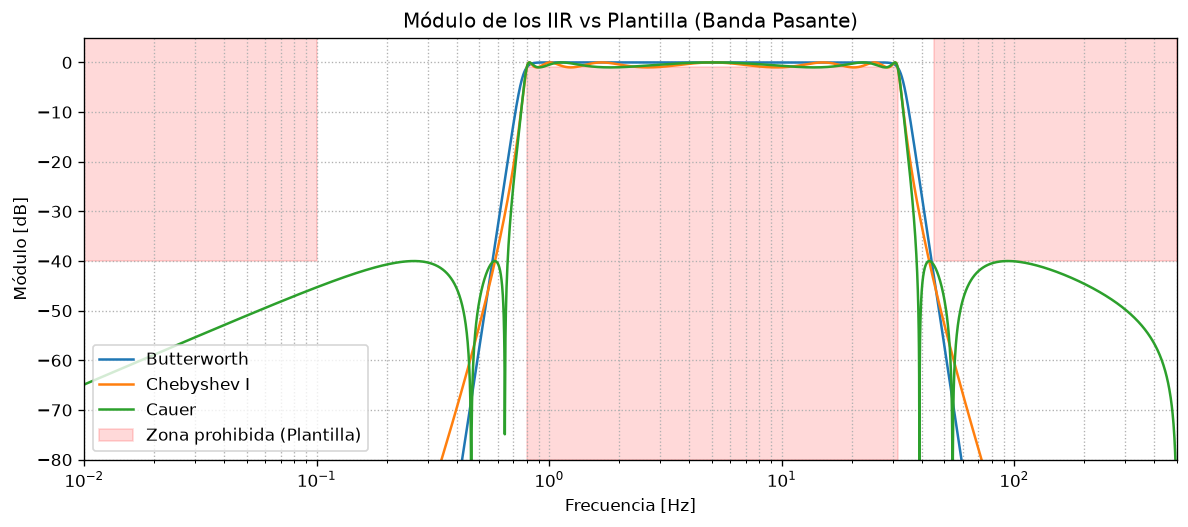

In [2]:
# ============================================================
# 2. DISEÑO Y EVALUACIÓN DE FILTROS IIR
# ============================================================
sos_butt = sig.iirdesign(
    wp, ws, gpass=ripple, gstop=atenuacion, ftype='butter', output='sos', fs=fs
)
sos_cheb = sig.iirdesign(
    wp, ws, gpass=ripple, gstop=atenuacion, ftype='cheby1', output='sos', fs=fs
)
sos_cauer = sig.iirdesign(
    wp, ws, gpass=ripple, gstop=atenuacion, ftype='ellip', output='sos', fs=fs
)

filtros_iir = {
    'Butterworth': sos_butt,
    'Chebyshev I': sos_cheb,
    'Cauer': sos_cauer,
}
colores = {
    'Butterworth': 'tab:blue',
    'Chebyshev I': 'tab:orange',
    'Cauer': 'tab:green',
}

print('--- ORDEN DE LOS FILTROS IIR ---')
for nombre, sos in filtros_iir.items():
    print(f'{nombre}: {sos.shape[0]} secciones -> orden {2*sos.shape[0]}')

# Vectores de frecuencia para análisis
f = np.logspace(-2, np.log10(nyq_frec), 5000)
respuestas_iir = {}
for nombre, sos in filtros_iir.items():
    w, H = sig.sosfreqz(sos, worN=f, fs=fs)
    respuestas_iir[nombre] = H


# Función auxiliar para dibujar las zonas prohibidas de la plantilla
def dibujar_plantilla(ax, f_min, f_max, y_min=-80, y_max=5):
    ax.fill_between([f_min, ws1], -atenuacion, y_max, color='red', alpha=0.15)
    ax.fill_between([wp1, wp2], y_min, -ripple, color='red', alpha=0.15)
    ax.fill_between(
        [ws2, f_max],
        -atenuacion,
        y_max,
        color='red',
        alpha=0.15,
        label='Zona prohibida (Plantilla)',
    )


# Gráfico de Módulo IIR (Eje logarítmico)
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre, H in respuestas_iir.items():
    ax.semilogx(
        f, 20 * np.log10(np.abs(H) + 1e-12), label=nombre, color=colores[nombre]
    )
dibujar_plantilla(ax, f[0], nyq_frec)
ax.set_xlim(f[0], nyq_frec)
ax.set_ylim(-80, 5)
ax.set_title('Módulo de los IIR vs Plantilla (Banda Pasante)')
ax.set_xlabel('Frecuencia [Hz]')
ax.set_ylabel('Módulo [dB]')
ax.grid(True, which='both', linestyle=':')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

Como se ve en la salida y en el gráfico de módulo, los tres filtros IIR esquivan sin problemas las zonas rojas prohibidas de la plantilla, pero con marcadas diferencias en la complejidad que necesitan:
- **Cauer** es el más eficiente de todos: con apenas **5 secciones SOS (orden 10)** clava las transiciones gracias a permitir ese rebote en la banda de rechazo en torno a los $-40\text{ dB}$ (se ven claramente los ceros de transmisión donde el módulo cae en picada hacia $-\infty\text{ dB}$).
- **Chebyshev Tipo I** se ubica en el medio con **7 secciones SOS (orden 14)**, mostrando una caída limpia y monótona en las bandas de detención a costa de un rizado de hasta $1\text{ dB}$ dentro de la banda de paso.
- **Butterworth** necesita **15 secciones SOS (orden 30)** —tres veces más que Cauer— porque al exigirle planicidad máxima dentro de la banda pasante su pendiente de caída inicial es mucho más progresiva.

---

### **3.3 Diseño y Evaluación de Filtros FIR**

Para la familia FIR fijamos un número impar de coeficientes `cant_coef = 1501` (orden $1500$, filtro Tipo I simétrico) para tener un buen compromiso entre selectividad en baja frecuencia y costo de cómputo, lo que nos deja un retardo de grupo exacto de:

$$\tau_g = \frac{1501 - 1}{2} = 750\text{ muestras} = 0.750\text{ s}$$

Diseñamos dos variantes con este mismo orden para compararlas de igual a igual:
1. **FIR por ventana (`firwin2`):** pasando como puntos de corte los valores intermedios de cada banda de transición ($c_1 = \frac{f_{s1}+f_{p1}}{2} = 0.45\text{ Hz}$ y $c_2 = \frac{f_{p2}+f_{s2}}{2} = 38.25\text{ Hz}$) y aplicando una ventana de Kaiser con $\beta = 4.0$.
2. **FIR por cuadrados mínimos (`firls`):** especificando los bordes de las bandas $[0, f_{s1}, f_{p1}, f_{p2}, f_{s2}, f_{\text{Nyquist}}]$. Como `firls` minimiza el error solo en las bandas especificadas, con un orden tan alto ($N=1501$) y transiciones tan angostas respecto a $f_s$, dejar las transiciones totalmente libres puede generar ganancias muy grandes en esas zonas no especificadas; para evitarlo, se incluyeron las bandas de transición con un peso bajo (`weight=[1, 0.01, 1, 0.01, 1]`), manteniendo la respuesta acotada y estable.

--- INFORMACIÓN DE LOS FILTROS FIR ---
FIR ventana: 1501 coeficientes, retardo = 750 muestras = 0.750 s
FIR firls: 1501 coeficientes, retardo = 750 muestras = 0.750 s


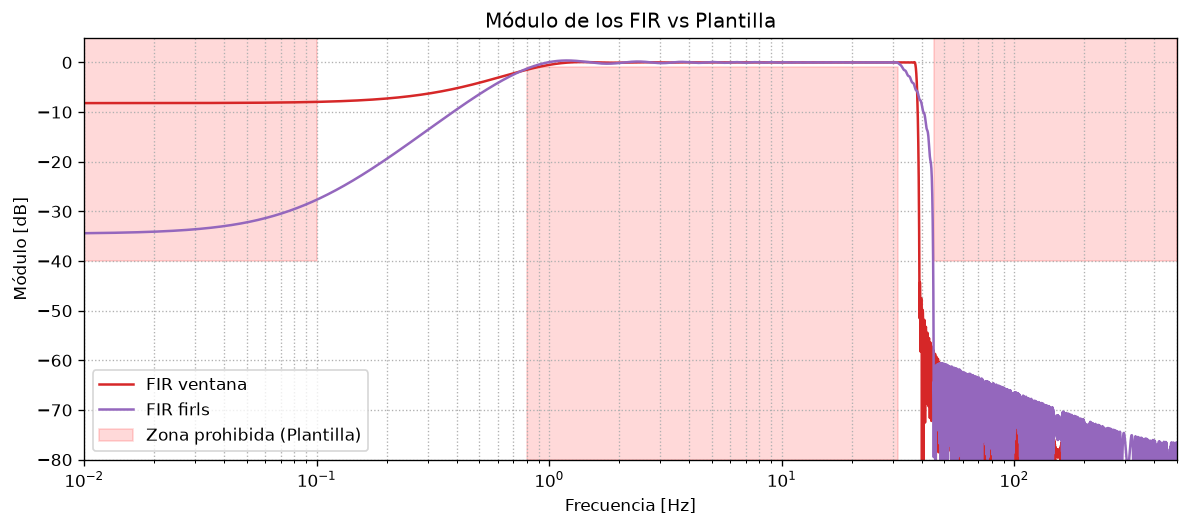

In [3]:
# ============================================================
# 3. DISEÑO Y EVALUACIÓN DE FILTROS FIR
# ============================================================
cant_coef = 1501  # Orden óptimo y razonable para los FIR (Tipo I, impar)
demora = (cant_coef - 1) // 2

# Diseñamos un FIR por método de Ventana (Kaiser) y otro por Mínimos Cuadrados (firls)
c1, c2 = (ws1 + wp1) / 2, (wp2 + ws2) / 2
h_win = sig.firwin2(
    cant_coef,
    [0, c1, c1, c2, c2, nyq_frec],
    [0, 0, 1, 1, 0, 0],
    window=('kaiser', 4.0),
    fs=fs,
)
h_ls = sig.firls(
    cant_coef,
    [0, ws1, ws1, wp1, wp1, wp2, wp2, ws2, ws2, nyq_frec],
    [0, 0,   0,   1,   1,   1,   1,   0,   0,   0],
    weight=[1, 0.01, 1, 0.01, 1],
    fs=fs,
)

filtros_fir = {'FIR ventana': h_win, 'FIR firls': h_ls}
colores_fir = {'FIR ventana': 'tab:red', 'FIR firls': 'tab:purple'}

print('--- INFORMACIÓN DE LOS FILTROS FIR ---')
for nombre, h in filtros_fir.items():
    print(
        f'{nombre}: {len(h)} coeficientes, retardo = {demora} muestras ='
        f' {demora/fs:.3f} s'
    )

respuestas_fir = {}
for nombre, h in filtros_fir.items():
    w, H = sig.freqz(h, worN=f, fs=fs)
    respuestas_fir[nombre] = H

# Gráfico de Módulo FIR
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre, H in respuestas_fir.items():
    ax.semilogx(
        f,
        20 * np.log10(np.abs(H) + 1e-12),
        label=nombre,
        color=colores_fir[nombre],
    )
dibujar_plantilla(ax, f[0], nyq_frec)
ax.set_xlim(f[0], nyq_frec)
ax.set_ylim(-80, 5)
ax.set_title('Módulo de los FIR vs Plantilla')
ax.set_xlabel('Frecuencia [Hz]')
ax.set_ylabel('Módulo [dB]')
ax.grid(True, which='both', linestyle=':')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

Acá aparece una diferencia muy interesante respecto a los IIR:
- En la **transición superior** ($31.5\text{ Hz}$ a $45.0\text{ Hz}$, donde el ancho de transición es de $13.5\text{ Hz}$), con $1501$ coeficientes ambos filtros FIR caen súper rápido y superan holgadamente los $40\text{ dB}$ de atenuación antes de llegar a los $45\text{ Hz}$ (el de ventana Kaiser incluso baja de los $-50\text{ dB}$).
- En cambio, en la **transición inferior** ($0.1\text{ Hz}$ a $0.8\text{ Hz}$), el ancho de transición es de apenas $\Delta f = 0.7\text{ Hz}$ para una frecuencia de muestreo de $1000\text{ Hz}$. Como en un FIR la pendiente de caída depende directamente del largo de la respuesta al impulso en segundos ($1.5\text{ s}$ para $1501$ muestras), esa transición tan finita les queda muy exigente y la curva roza el borde de la zona prohibida inferior. Para que un FIR cayera de $0\text{ dB}$ a $-40\text{ dB}$ en solo $0.7\text{ Hz}$ sin tocar nada la plantilla harían falta varios miles de coeficientes más, con una demora de varios segundos. Aun así, como vamos a comprobar ahora en los gráficos temporales, esta caída en bajas frecuencias ya alcanza de sobra para planchar la línea de base en $0\text{ mV}$.

---

### **3.4 Aplicación de los Filtros a la Señal de ECG**

Procedemos a filtrar el registro completo (`ecg_one_lead`):
- Para los **tres filtros IIR** usamos `scipy.signal.sosfiltfilt` para tener fase cero sin demora.
- Para los **dos filtros FIR** aplicamos convolución rápida por bloques mediante `scipy.signal.oaconvolve` y recortamos las primeras `d = 750` muestras (`y[d:]`) para compensar el retardo de grupo lineal y dejar la salida sincronizada con el ECG original.

In [4]:
# ============================================================
# 4. APLICACIÓN DE LOS FILTROS AL ECG
# ============================================================
# IIR con fase cero (sosfiltfilt)
ecg_butt_ff = sig.sosfiltfilt(sos_butt, ecg_one_lead)
ecg_cheb_ff = sig.sosfiltfilt(sos_cheb, ecg_one_lead)
ecg_cauer_ff = sig.sosfiltfilt(sos_cauer, ecg_one_lead)


# FIR compensando la demora lineal (fase lineal perfecta)
def filtrar_fir(h, x):
    d = (len(h) - 1) // 2
    y = sig.oaconvolve(x, h, mode='full')[: len(x) + d]
    return y[d:]  # Desplaza y alinea temporalmente


ecg_win = filtrar_fir(h_win, ecg_one_lead)
ecg_ls = filtrar_fir(h_ls, ecg_one_lead)

# Para graficar los resultados fácilmente
senales = {
    'Butterworth': (ecg_butt_ff, 'tab:blue'),
    'Chebyshev I': (ecg_cheb_ff, 'tab:orange'),
    'Cauer': (ecg_cauer_ff, 'tab:green'),
    'FIR ventana': (ecg_win, 'tab:red'),
    'FIR firls': (ecg_ls, 'tab:purple'),
}

print("Filtrado finalizado correctamente para los 5 diseños (3 IIR + 2 FIR).")

Filtrado finalizado correctamente para los 5 diseños (3 IIR + 2 FIR).


---

### **3.5 Evaluación Visual por Regiones (Zonas Limpias vs. Zonas con Ruido)**

Definimos la función `graficar_regiones`, que arma dos paneles apilados por cada intervalo de interés: arriba compara los tres filtros IIR contra el ECG original (en gris de fondo) y abajo hace lo mismo con los dos filtros FIR.

Primero evaluamos las **zonas estables / sin ruido evidente** (muestras `4000 a 5500` y `10000 a 11000`), donde el objetivo es verificar que el filtrado sea **inocuo** y no deforme la señal cuando ya viene limpia.

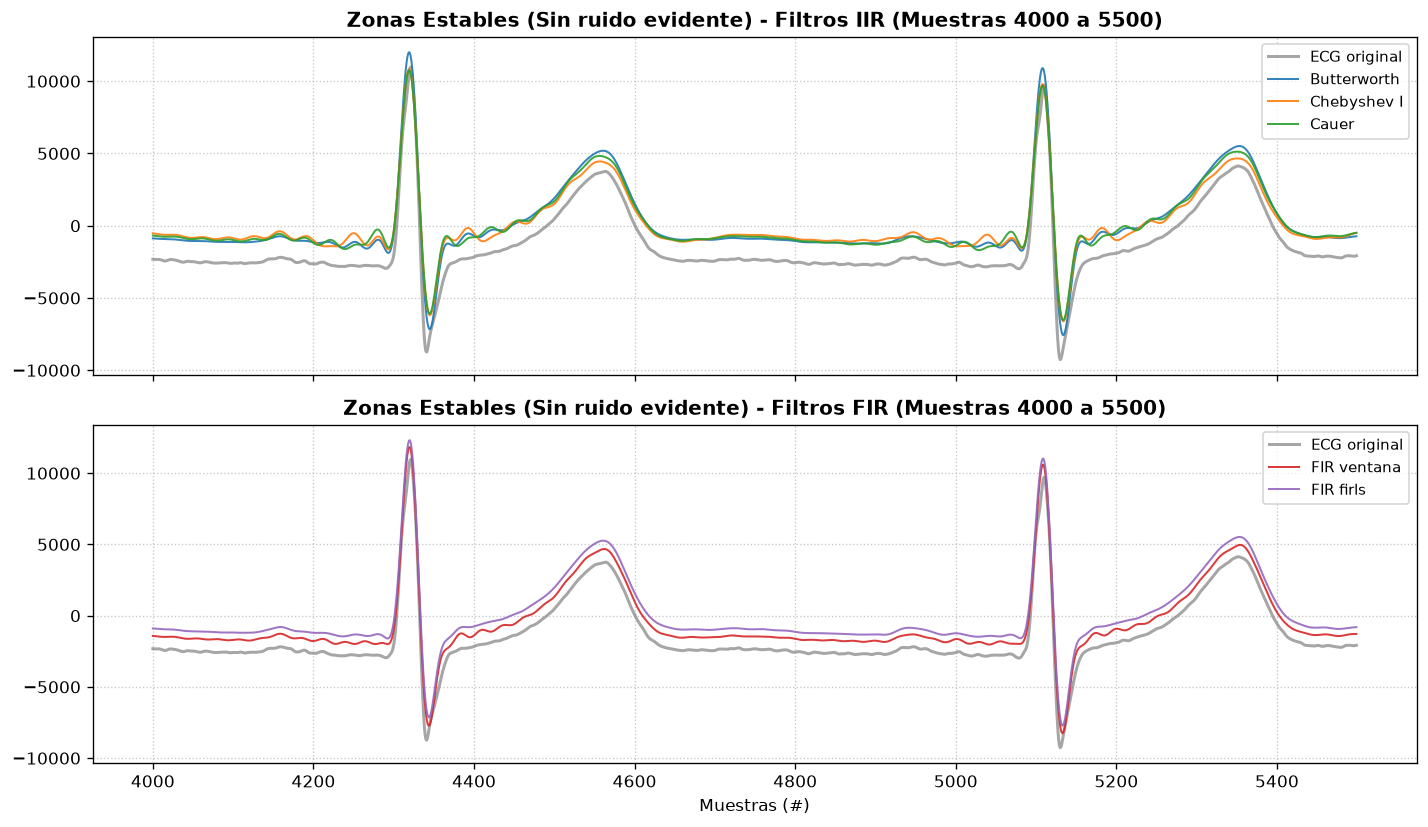

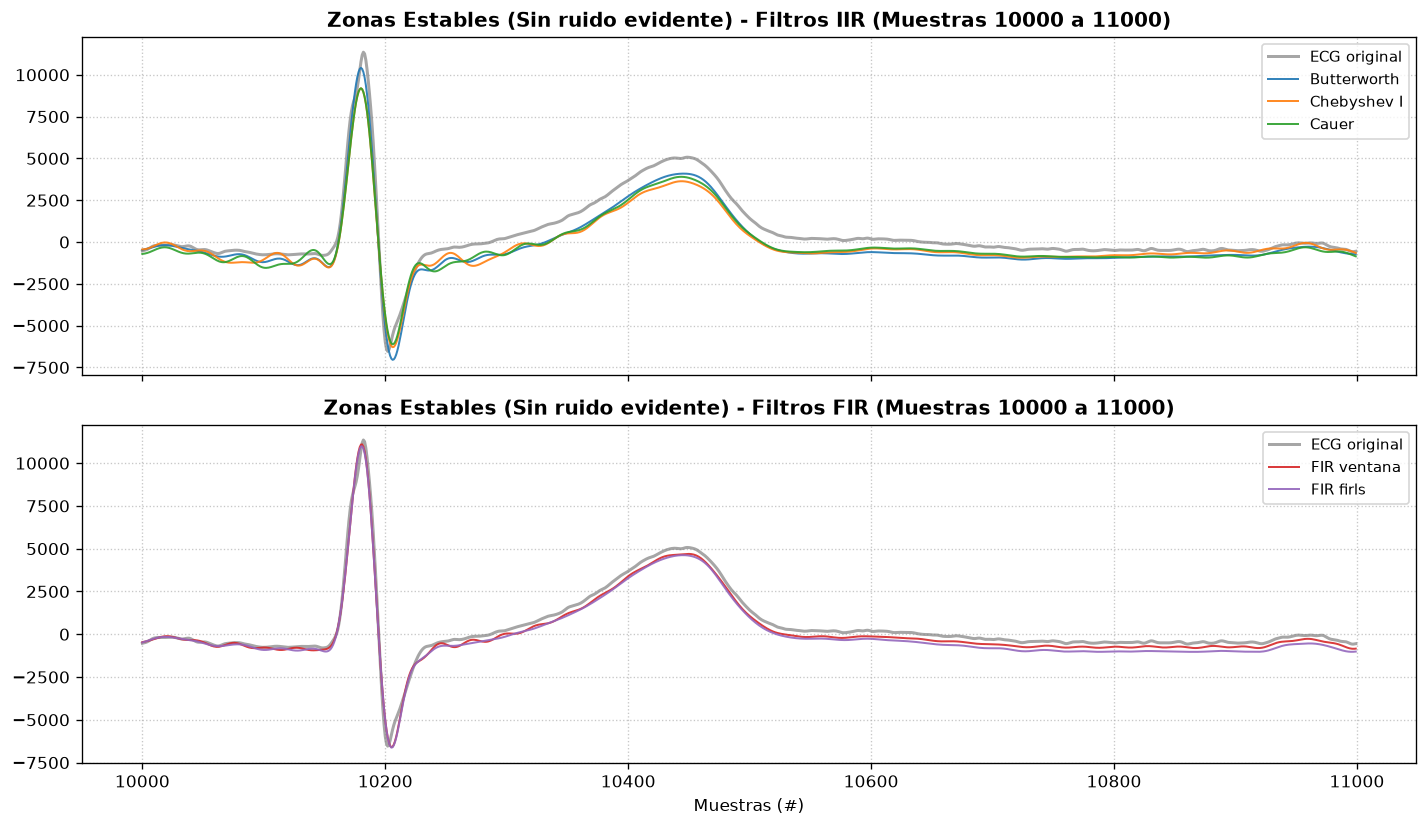

In [5]:
# ============================================================
# 5. GRÁFICOS DE ZOOMS (Zonas limpias y con ruido)
# ============================================================
def graficar_regiones(regiones, titulo_grupo):
    cant = ecg_one_lead.shape[0]
    for ini, fin in regiones:
        ini, fin = int(max(0, ini)), int(min(cant, fin))
        if fin <= ini:
            continue
        zoom = np.arange(ini, fin)

        fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

        # ECG original de fondo en ambos paneles
        for ax in axs:
            ax.plot(
                zoom,
                ecg_one_lead[zoom],
                label='ECG original',
                color='gray',
                linewidth=1.8,
                alpha=0.7,
            )

        # Ploteamos IIR arriba y FIR abajo
        for nombre, (x, col) in senales.items():
            ax = axs[0] if nombre in filtros_iir else axs[1]
            ax.plot(
                zoom, x[zoom], label=nombre, color=col, linewidth=1.2, alpha=0.9
            )

        axs[0].set_title(
            f'{titulo_grupo} - Filtros IIR (Muestras {ini} a {fin})',
            fontweight='bold',
        )
        axs[1].set_title(
            f'{titulo_grupo} - Filtros FIR (Muestras {ini} a {fin})',
            fontweight='bold',
        )
        axs[1].set_xlabel('Muestras (#)')

        for ax in axs:
            ax.legend(loc='upper right', fontsize=9)
            ax.grid(True, linestyle=':', alpha=0.7)

        plt.tight_layout()
        plt.show()


# A. Regiones estables / sin ruido (ej: tramos intermedios limpios)
regs_limpias = ([4000, 5500], [10000, 11000])
graficar_regiones(regs_limpias, 'Zonas Estables (Sin ruido evidente)')

Ahora pasamos a evaluar las **zonas críticas con ruido e interferencias**, ubicadas durante los minutos de mayor exigencia física de la prueba de esfuerzo:
- **Minuto $5.0$ a $5.2$** (muestras `300.000` a `312.000`).
- **Minuto $12.0$ a $12.4$** (muestras `720.000` a `744.000`).

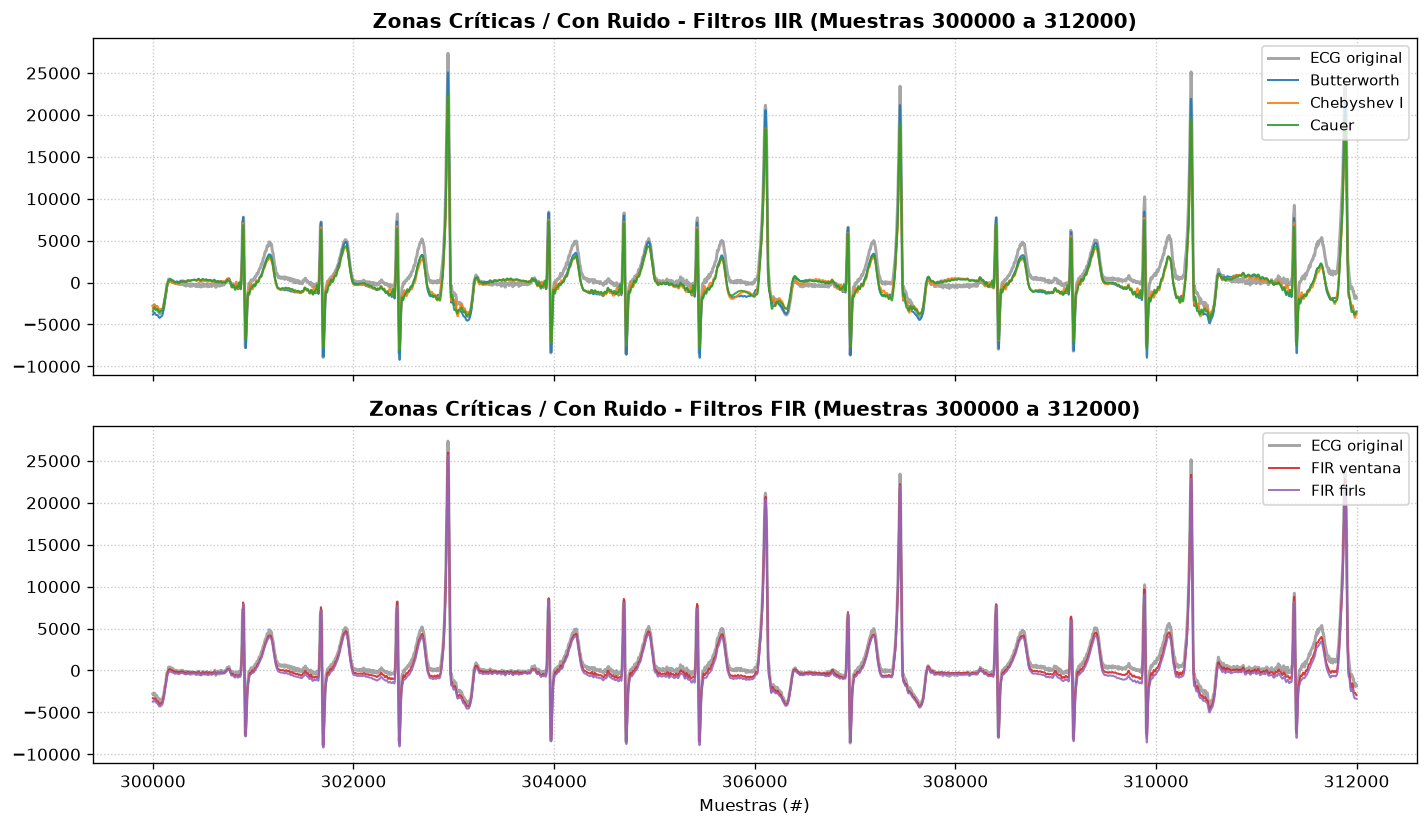

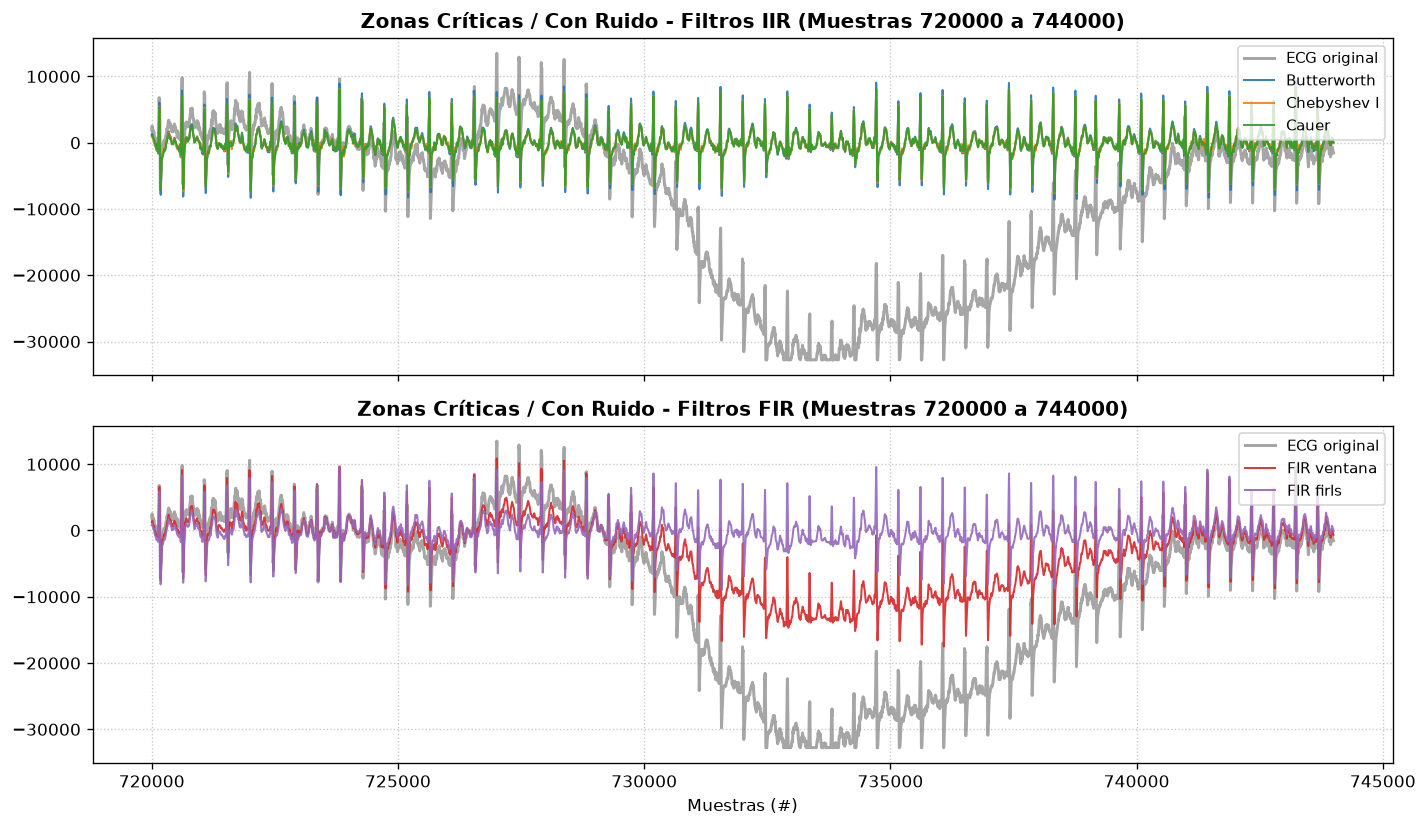

In [6]:
# B. Regiones con ruido e interferencias (convertidas de minutos a muestras)
regs_ruido = [
    np.array([5.0, 5.2]) * 60 * fs,
    np.array([12.0, 12.4]) * 60 * fs,
]
graficar_regiones(regs_ruido, 'Zonas Críticas / Con Ruido')

---

## **4. Análisis de Resultados**

### **4.1 Comparación de Orden Computacional y Retardo**

En la siguiente tabla resumimos las características que obtuvimos para cada uno de los cinco filtros diseñados:

| Filtro | Secciones SOS / Coeficientes | Orden Equivalente | Retardo Temporal $\tau_g$ | Estrategia de Fase |
| :--- | :---: | :---: | :---: | :---: |
| **Butterworth (IIR)** | 15 secciones SOS | Orden 30 | $0\text{ s}$ | Fase cero bidireccional (`sosfiltfilt`) |
| **Chebyshev Tipo I (IIR)** | 7 secciones SOS | Orden 14 | $0\text{ s}$ | Fase cero bidireccional (`sosfiltfilt`) |
| **Cauer / Elíptico (IIR)** | 5 secciones SOS | Orden 10 | $0\text{ s}$ | Fase cero bidireccional (`sosfiltfilt`) |
| **FIR Ventana (Kaiser)** | 1501 coeficientes | Orden 1500 | $750\text{ muestras} = 0.750\text{ s}$ | Fase lineal estricta (compensado) |
| **FIR Mínimos Cuadrados (`firls`)** | 1501 coeficientes | Orden 1500 | $750\text{ muestras} = 0.750\text{ s}$ | Fase lineal estricta (compensado) |

La diferencia en costo computacional es clarísima: mientras que el filtro de **Cauer** resuelve toda la plantilla con apenas 5 bicuadráticas (orden 10), los filtros **FIR** necesitan 1501 coeficientes para acercarse a las exigencias de transición. Dentro de los IIR también se nota bien el compromiso teórico: al pasar de una respuesta plana (Butterworth, orden 30) a una con rizado en banda de paso (Chebyshev I, orden 14) y finalmente a rizado en ambas bandas (Cauer, orden 10), el número de secciones necesarias se reduce a un tercio.

### **4.2 Desempeño en el Dominio del Tiempo**

Al analizar los gráficos temporales sobre `ecg_lead` podemos destacar tres puntos principales:

1. **Inocuidad en las zonas estables (Muestras 4000–5500 y 10000–11000):**  
   En estos segmentos donde el paciente todavía no metía tanto ruido muscular, la señal filtrada (tanto con los tres IIR como con los dos FIR) calza prácticamente encima del trazo original, con la única diferencia de que le quita el offset o deriva lenta y centra la línea isoeléctrica en $0$. No se pierde amplitud en los picos R, no se ensancha el complejo QRS y no aparecen ondulaciones raras (efecto Gibbs) en el segmento ST ni antes de la onda P. Además, se ve que las tres curvas IIR (azul, naranja y verde) y las dos FIR (roja y violeta) dan resultados visuales casi indistinguibles entre sí.

2. **Eliminación de deriva de línea de base y ruido EMG en zonas críticas (Minutos 5.0–5.2 y 12.0–12.4):**  
   En los tramos de esfuerzo fuerte, el ECG crudo (en gris) se desvía muchísimo hacia arriba y hacia abajo por la respiración y el movimiento de los electrodos, llegando a excursiones de más de $\pm 30\,000$ cuentas, además de tener un serrucho de alta frecuencia constante encima. Tanto los filtros IIR como los FIR logran planchar esa deriva lenta llevando la base del latido otra vez alrededor del cero, y limpian el ruido de alta frecuencia permitiendo distinguir cada latido y la regularidad del ritmo cardíaco.  
   Un detalle que se nota en el minuto $12.0\text{–}12.4$ (alrededor de la muestra $737\,000$, donde hay un salto abrupto enorme del electrodo) es que ninguna técnica lineal puede borrar del todo un escalón tan violento porque parte de la energía de ese tirón mecánico cae entre $1$ y $10\text{ Hz}$ (justo adentro de nuestra banda de paso). Sin embargo, el filtro se recupera rápido después del transitorio y vuelve a estabilizar la línea de base.

3. **Alineación temporal perfecta:**  
   Gracias al uso de `sosfiltfilt` en los IIR y al desplazamiento explícito de $d = 750$ muestras en los FIR, en todos los zooms los picos R filtrados coinciden exactamente en la misma muestra que los picos R del registro original.

---

## **5. Conclusiones y Aprendizajes**

- **Eficiencia computacional vs. causalidad en los IIR:** Comprobamos que los filtros IIR (y muy especialmente la aproximación de Cauer de orden 10) requieren muchísimas menos operaciones que un FIR equivalente. Sin embargo, para poder usarlos en ECG sin deformar la onda T ni el segmento ST por su fase no lineal, tuvimos que recurrir al filtrado bidireccional (`sosfiltfilt`). Esto funciona bárbaro cuando ya tenemos todo el estudio grabado (*offline*), pero no se podría aplicar de forma directa muestra a muestra en un monitor en tiempo real porque necesita conocer el futuro de la señal.

- **Fase lineal garantizada en los FIR:** Los filtros FIR Tipo I nos aseguran de fábrica que no van a meter distorsión de fase porque atrasan todas las frecuencias por igual ($0.75\text{ s}$ en nuestro diseño de 1501 coeficientes). En el análisis *offline* bastó con correr el vector 750 muestras a la izquierda, y en un sistema en tiempo real se podría implementar perfectamente asumiendo ese pequeño atraso constante de tres cuartos de segundo en la pantalla.

- **Conexión entre el análisis espectral (TS5) y el diseño del filtro (TS7):** Haber medido en la TS5 que casi toda la energía útil del ECG estaba concentrada antes de los $35\text{ Hz}$ nos dio un criterio concreto para ubicar $f_{p2} = 31.5\text{ Hz}$ y $f_{s2} = 45.0\text{ Hz}$. Esto nos permitió barrer el ruido muscular de alta frecuencia y los $50\text{ Hz}$ de línea conservando intacta la forma de los complejos QRS y de las ondas P y T.